#TEXT RECOGNITION MODEL


Part 1: Imports and necessary modules

In [19]:
#Connecting Google Drive
from google.colab import drive
drive.mount('/content/drive')
import os

#Ability to render form images
import cv2
import matplotlib.pyplot as plt

#Ability to read xml files
import xml.etree.ElementTree as ET

#JSON capabilities
import json

#Numpy
import numpy as np

#Method used to randomly shuffle writers into datasets
from sklearn.model_selection import GroupShuffleSplit


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


###Task #1: Connect Google Colab to the IAM Database in our Google Drive Folder

In [2]:
BASE = "/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files"

RAW = os.path.join(BASE, "Raw Data")
PROCESSED = os.path.join(BASE, "Processed Data")

RAW_FORMS = os.path.join(RAW, "forms")
RAW_ASCII = os.path.join(RAW, "ascii")
RAW_XML = os.path.join(RAW, "xml")

# Check that the directories exist
for path in [RAW,PROCESSED,RAW_FORMS,RAW_ASCII]:
    print(path, "exists:", os.path.exists(path))

# List files in the forms directory
print("\nFirst 10 files in IAM forms:")
print(os.listdir(RAW_FORMS)[:10])

/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Raw Data exists: True
/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Processed Data exists: True
/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Raw Data/forms exists: True
/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Raw Data/ascii exists: True

First 10 files in IAM forms:
['a01-000u.png', 'a01-000x.png', 'a01-003.png', 'a01-003u.png', 'a01-003x.png', 'a01-007.png', 'a01-007u.png', 'a01-007x.png', 'a01-011.png', 'a01-011u.png']


Testing to see if this can access an IAM form file, and the xml file can correspond to the correct image file:

In [3]:
def name(file_name):
    file_name = file_name.split(".")[0]
    return file_name

Number of images: 529
a01-000u


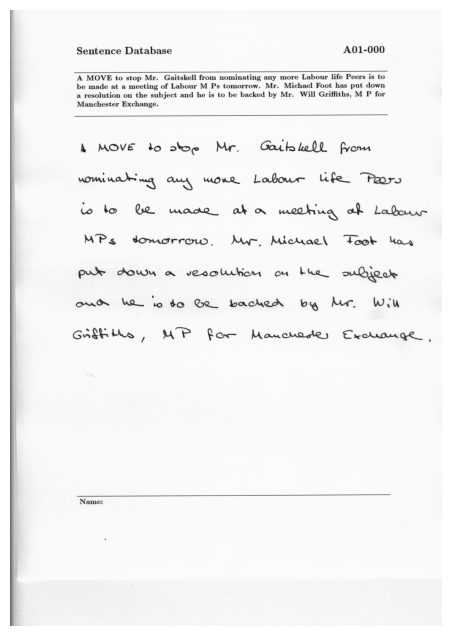

Number of XML files: 1539
Root tag: form
Root attributes: {'created': '2002-01-14', 'height': '3542', 'id': 'a01-000u', 'last-modified': '2002-07-17', 'skew': '287', 'status': 'final', 'version': '3.0_beta', 'width': '2479', 'writer-id': '000'}
Number of word elements: 52
{'id': 'a01-000u-00-00', 'sentence-start': 'yes', 'tag': 'AT', 'text': 'A'}
{'id': 'a01-000u-00-01', 'tag': 'NN', 'text': 'MOVE'}
{'id': 'a01-000u-00-02', 'tag': 'TO', 'text': 'to'}
{'id': 'a01-000u-00-03', 'tag': 'VB', 'text': 'stop'}
{'id': 'a01-000u-00-04', 'tag': 'NPT', 'text': 'Mr.'}


In [4]:
image_files = [
    f for f in os.listdir(RAW_FORMS)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
]

print("Number of images:", len(image_files))

# Load the first image
image_path = os.path.join(RAW_FORMS, image_files[0])
image = cv2.imread(image_path)
image_name = name(image_files[0])
print(image_name)

# Display it
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(14, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

#Create XML files list:
xml_files = [
    f for f in os.listdir(RAW_XML)
    if f.endswith(".xml")
]
#This is expected to be a different number than 529, since I have only downloaded Forms A-D.
print("Number of XML files:", len(xml_files))

sample_xml = os.path.join(RAW_XML, image_name+".xml")
tree = ET.parse(sample_xml)
root = tree.getroot()

print("Root tag:", root.tag)
print("Root attributes:", root.attrib)

# Find word elements and inspect the first few
words = root.findall(".//word")
print("Number of word elements:", len(words))

for word in words[:5]:
    print(word.attrib)

###Task #2: Create a Python Dictionary to correspond images with xml files

In [5]:
images_by_id = {
    name(f): os.path.join(RAW_FORMS, f)
    for f in image_files
}
xml_by_id = {
    name(f): os.path.join(RAW_XML, f)
    for f in xml_files
}

dataset = {
    image_id: {
        "image": images_by_id[image_id],
        "xml": xml_by_id[image_id]
    }
    for image_id in images_by_id if image_id in xml_by_id.keys()}

print(len(dataset))
print(dataset['b04-103'])

529
{'image': '/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Raw Data/forms/b04-103.png', 'xml': '/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Raw Data/xml/b04-103.xml'}


###Task #3: Process Each Image/XML Pair

In [6]:
def process_image_xml(image_path, xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    words = []

    for word in root.iter():
        if word.tag.split("}")[-1].lower() != "word":
            continue

        text = word.attrib.get("text", "").strip()
        if not text:
            continue

        # In IAM XML, word elements often don't have direct coordinates.
        # Instead, coordinates are on the child <cmp> (component) elements.
        cmps = word.findall(".//cmp")
        if not cmps:
            # Try finding bounding box on the word itself if available
            coords = word.attrib
            if not all(k in coords for k in ("x", "y", "width", "height")):
                continue
            x, y = int(coords["x"]), int(coords["y"])
            w, h = int(coords["width"]), int(coords["height"])
        else:
            # Find the bounding box containing all child component elements
            xs = [int(c.attrib["x"]) for c in cmps if "x" in c.attrib]
            ys = [int(c.attrib["y"]) for c in cmps if "y" in c.attrib]
            ws = [int(c.attrib["width"]) for c in cmps if "width" in c.attrib]
            hs = [int(c.attrib["height"]) for c in cmps if "height" in c.attrib]

            if not (xs and ys and ws and hs):
                continue

            x = min(xs)
            y = min(ys)
            w = max(x_val + w_val for x_val, w_val in zip(xs, ws)) - x
            h = max(y_val + h_val for y_val, h_val in zip(ys, hs)) - y

        if w <= 0 or h <= 0:
            continue

        points = [
            [x,     y],
            [x + w, y],
            [x + w, y + h],
            [x,     y + h]
        ]

        words.append({
            "text": text,
            "points": points
        })

    return {
        "image": image_path,
        "words": words
    }

In [7]:
#CREATE THE PROCESSED DATASET DICTIONARY
#Takes about a minute to process...
processed_dataset = {}
errors = {}

for image_id, paths in dataset.items():
    try:
        processed_dataset[image_id] = process_image_xml(
            paths["image"],
            paths["xml"]
        )

    except Exception as e:
        errors[image_id] = str(e)

print("Successfully processed:", len(processed_dataset))
print("Errors:", len(errors))

if errors:
    for image_id, error in list(errors.items())[:10]:
        print(image_id, ":", error)

Successfully processed: 529
Errors: 0


In [8]:
print("Image: ",processed_dataset['b04-103']['image'])
print("First 5 Words: ",processed_dataset['b04-103']['words'][:5])

Image:  /content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Raw Data/forms/b04-103.png
First 5 Words:  [{'text': 'Up', 'points': [[351, 719], [421, 719], [421, 897], [351, 897]]}, {'text': 'and', 'points': [[469, 707], [573, 707], [573, 802], [469, 802]]}, {'text': 'down', 'points': [[633, 697], [799, 697], [799, 810], [633, 810]]}, {'text': 'the', 'points': [[885, 719], [982, 719], [982, 806], [885, 806]]}, {'text': 'country', 'points': [[1048, 689], [1275, 689], [1275, 877], [1048, 877]]}]


###Task 4: Convert to readable format for PaddleOCR

In [13]:
def to_paddle_annotation(image_data):
    """
    Convert one processed image dictionary entry into
    PaddleOCR's detection annotation format.
    """
    annotations = []

    for word in image_data["words"]:
        annotations.append({
            "transcription": word["text"],
            "points": word["points"]
        })

    return (
        image_data["image"]
        + "\t"
        + json.dumps(annotations, ensure_ascii=False)
    )

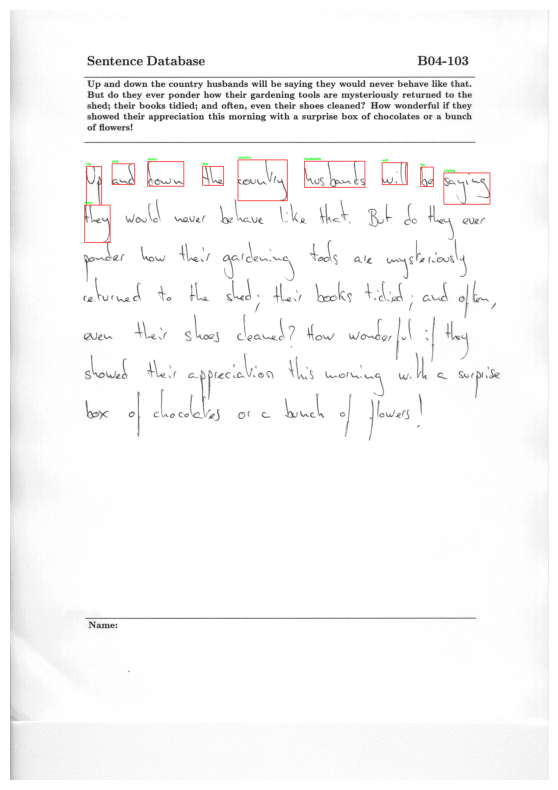

In [14]:
#Testing on a sample image first
sample_id = "b04-103"
sample = processed_dataset[sample_id]

image = cv2.imread(sample["image"])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for word in sample["words"][:10]:
    points = word["points"]

    # Draw the bounding box
    polygon = np.array(points, dtype=np.int32)
    cv2.polylines(image, [polygon], True, (255, 0, 0), 2)

    # Draw the transcription above the box
    x, y = points[0]
    cv2.putText(
        image, word["text"], (x, y - 5),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
            )

plt.figure(figsize=(15, 10))
plt.imshow(image)
plt.axis("off");

In [15]:
#Processing all images
annotation_lines = [
    to_paddle_annotation(image_data)
    for image_data in processed_dataset.values()
]

print(annotation_lines[0][:1000])

/content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Raw Data/forms/a01-000u.png	[{"transcription": "A", "points": [[408, 768], [435, 768], [435, 819], [408, 819]]}, {"transcription": "MOVE", "points": [[507, 766], [720, 766], [720, 814], [507, 814]]}, {"transcription": "to", "points": [[796, 764], [866, 764], [866, 814], [796, 814]]}, {"transcription": "stop", "points": [[919, 757], [1085, 757], [1085, 835], [919, 835]]}, {"transcription": "Mr.", "points": [[1185, 754], [1311, 754], [1311, 815], [1185, 815]]}, {"transcription": "Gaitskell", "points": [[1438, 746], [1820, 746], [1820, 819], [1438, 819]]}, {"transcription": "from", "points": [[1896, 757], [2069, 757], [2069, 829], [1896, 829]]}, {"transcription": "nominating", "points": [[395, 932], [836, 932], [836, 1032], [395, 1032]]}, {"transcription": "any", "points": [[901, 958], [1048, 958], [1048, 1037], [901, 1037]]}, {"transcription": "more", "points": [[1112, 958], [1320, 958], [1320, 1000], [1112, 1000]]}, {

In [16]:
#Saving annotated text to Google Drive
PROCESSED = (
    "/content/drive/MyDrive/ECE 539 Integration Project/"
    "IAM Database Files/Processed Data"
)

os.makedirs(PROCESSED, exist_ok=True)

annotation_path = os.path.join(PROCESSED, "all_annotations.txt")

with open(annotation_path, "w", encoding="utf-8") as f:
    for line in annotation_lines:
        f.write(line + "\n")

print("Saved annotations to:", annotation_path)
print("Number of annotated images:", len(annotation_lines))

Saved annotations to: /content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Processed Data/all_annotations.txt
Number of annotated images: 529


###Task 5: Create the Training, Validation, and Test datasets
(Splitting by writer)

In [18]:
writer_by_image = {}

for image_id, paths in dataset.items():
    root = ET.parse(paths["xml"]).getroot()
    writer_id = root.attrib.get("writer-id")
    if writer_id is None:
        raise ValueError(
            f"No writer ID ('writer-id') found in XML for {image_id}. "
            f"Root attributes: {root.attrib}"
        )

    writer_by_image[image_id] = writer_id

print("Images with writer IDs:", len(writer_by_image))
print("Example:", list(writer_by_image.items())[:5])

Images with writer IDs: 529
Example: [('a01-000u', '000'), ('a01-000x', '001'), ('a01-003', '002'), ('a01-003u', '000'), ('a01-003x', '003')]


In [20]:

# Use only images that were successfully processed
image_ids = list(processed_dataset.keys())

groups = np.array([
    writer_by_image[image_id]
    for image_id in image_ids
])

# First split: 80% train, 20% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(image_ids, groups=groups)
)

train_ids = [image_ids[i] for i in train_idx]
temp_ids = [image_ids[i] for i in temp_idx]

# Second split: divide temporary set equally into validation and test
temp_groups = groups[temp_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(temp_ids, groups=temp_groups)
)

val_ids = [temp_ids[i] for i in val_idx]
test_ids = [temp_ids[i] for i in test_idx]

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Testing images:", len(test_ids))

#None of the sets have overlapping writers, which is good. This prevents overfitting.

Training images: 441
Validation images: 48
Testing images: 40


In [22]:
def create_annotation_line(image_data):
    annotations = []

    for word in image_data["words"]:
        annotations.append({
            "transcription": word["text"],
            "points": word["points"]
        })

    return (
        image_data["image"]
        + "\t"
        + json.dumps(annotations, ensure_ascii=False)
    )


def save_split(image_ids, filename):
    output_path = os.path.join(PROCESSED, filename)

    with open(output_path, "w", encoding="utf-8") as f:
        for image_id in image_ids:
            line = create_annotation_line(
                processed_dataset[image_id]
            )
            f.write(line + "\n")

    print(f"Saved {len(image_ids)} images to {output_path}")


save_split(train_ids, "train.txt")
save_split(val_ids, "val.txt")
save_split(test_ids, "test.txt")

Saved 441 images to /content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Processed Data/train.txt
Saved 48 images to /content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Processed Data/val.txt
Saved 40 images to /content/drive/MyDrive/ECE 539 Integration Project/IAM Database Files/Processed Data/test.txt
